# How pandas, NumPy, and Matplotlib Work Together

Data analysis often involves three steps: organize the data, calculate useful results, and communicate those results. **pandas**, **NumPy**, and **Matplotlib** work well together because each library is designed for a different part of that process.

This notebook uses the Titanic passenger file `test.csv` in the `DA` folder. It contains passenger records, but no `Survived` column. The examples describe the records in this file and do not make claims about survival.

Install the libraries in the Python environment running Jupyter if needed:

```text
pip install pandas numpy matplotlib
```


## 1. The role of each library

| Library | Main role in this workflow | Examples in this notebook |
|---|---|---|
| **pandas** | Read, label, inspect, filter, and group tabular data | DataFrame, missing-value checks, category counts |
| **NumPy** | Perform numerical calculations on arrays | Mean, median, minimum, maximum, standard deviation |
| **Matplotlib** | Draw and format charts | Bar chart, histogram, and box plot |

The libraries can pass data to one another. A pandas column can be selected and cleaned, then converted to a NumPy array for calculations. The resulting summaries or cleaned values can then be plotted with Matplotlib. pandas also has plotting helpers that use Matplotlib behind the scenes; this notebook uses Matplotlib directly so each plotting step is visible.


## 2. Load and inspect a CSV with pandas

A CSV stores rows and columns as text. `pandas.read_csv` reads the file into a DataFrame, where each column has a label and each row has an index. Start by checking a few records, the table shape, the column names, and the data types. These checks show what the file contains before calculations begin.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt

candidates = [Path("test.csv"), Path("DA") / "test.csv"]
DATA_PATH = next((path for path in candidates if path.exists()), candidates[0])
if not DATA_PATH.exists():
    raise FileNotFoundError("Place test.csv beside this notebook or in the DA folder.")

df = pd.read_csv(DATA_PATH)
print("File:", DATA_PATH.resolve())
print("Rows and columns:", df.shape)
print("Columns:", df.columns.tolist())
print("Data types:")
print(df.dtypes)
display(df.head())


File: C:\Users\ashir\OneDrive\Desktop\Mirai\AKTU\Python\Python_fundas\DA\test.csv
Rows and columns: (418, 11)
Columns: ['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
Data types:
PassengerId      int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


Here, pandas handles reading and organizing the CSV. The file has 418 rows and 11 columns. Inspecting the headings also confirms that the file has no `Survived` column.


## 3. Check missing values with pandas

Missing values affect calculations. pandas represents blank CSV fields as missing values and provides `isna()` and `sum()` to count them. Decide how to handle missing entries based on the calculation: for a mean age, use the known ages and report how many values were included.


In [2]:
missing_by_column = df.isna().sum()
print("Missing values by column:")
print(missing_by_column)
print("\nKnown and missing ages:")
print("Known:", df["Age"].notna().sum())
print("Missing:", df["Age"].isna().sum())


Missing values by column:
PassengerId      0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64

Known and missing ages:
Known: 332
Missing: 86


## 4. Use NumPy to calculate numerical summaries

pandas selects the `Age` column and removes missing values. `to_numpy()` converts the remaining values into a NumPy array. NumPy then calculates numerical summaries. This division of work is useful: pandas manages labeled table data, while NumPy performs array-based numerical calculations.


In [3]:
known_ages = df["Age"].dropna().to_numpy()

mean_age = np.mean(known_ages)
median_age = np.median(known_ages)
minimum_age = np.min(known_ages)
maximum_age = np.max(known_ages)
std_age = np.std(known_ages)

print("Records included:", known_ages.size)
print(f"Mean age: {mean_age:.2f} years")
print(f"Median age: {median_age:.2f} years")
print(f"Minimum age: {minimum_age:.2f} years")
print(f"Maximum age: {maximum_age:.2f} years")
print(f"Standard deviation: {std_age:.2f} years")


Records included: 332
Mean age: 30.27 years
Median age: 27.00 years
Minimum age: 0.17 years
Maximum age: 76.00 years
Standard deviation: 14.16 years


The mean and median describe different aspects of the data. The mean uses every value and can be influenced by unusually high or low values. The median is the middle value after sorting. The minimum and maximum show the observed endpoints. These summaries describe only the 332 records with a known age.


## 5. Use pandas to count categories and Matplotlib to plot them

`value_counts()` is a pandas operation that counts records in each ticket class. Matplotlib receives the class labels and counts and draws a bar chart. A bar chart is suitable because ticket class is categorical.


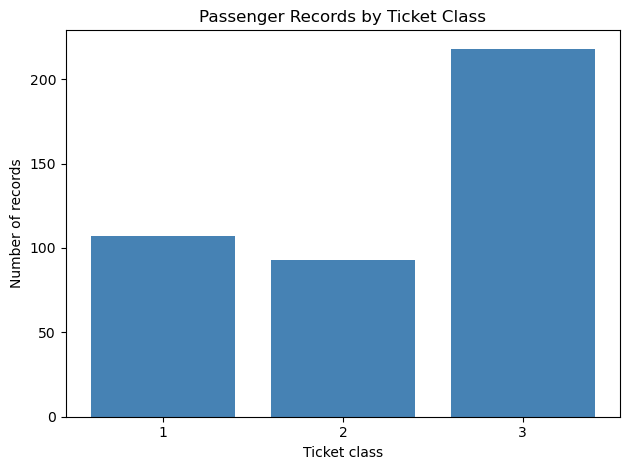

Pclass
1    107
2     93
3    218
Name: count, dtype: int64


In [4]:
class_counts = df["Pclass"].value_counts().sort_index()

fig, ax = plt.subplots()
ax.bar(class_counts.index.astype(str), class_counts.values, color="steelblue")
ax.set_title("Passenger Records by Ticket Class")
ax.set_xlabel("Ticket class")
ax.set_ylabel("Number of records")
plt.tight_layout()
plt.show()

print(class_counts)


The chart shows how many records in this file belong to each class. It does not show passenger outcomes. pandas prepared the counts; Matplotlib rendered them as a chart.


## 6. Use pandas to clean a column, NumPy to summarize it, and Matplotlib to display it

A histogram shows the distribution of numerical values. pandas selects known ages, NumPy supplies the mean, and Matplotlib displays the values in intervals called bins. The vertical line marks the mean age.


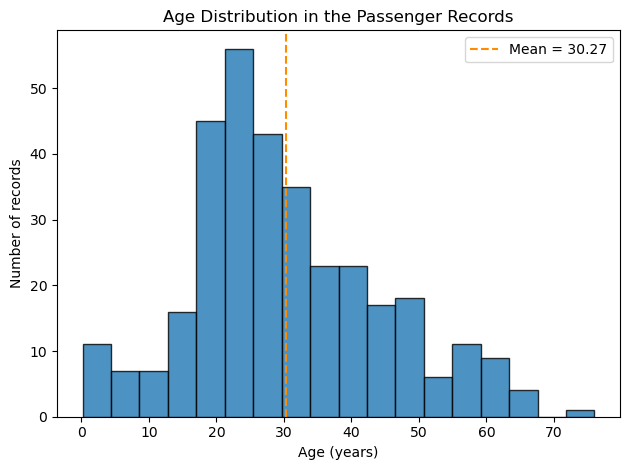

In [5]:
ages = df["Age"].dropna().to_numpy()
average_age = float(np.mean(ages))

fig, ax = plt.subplots()
ax.hist(ages, bins=18, edgecolor="black", alpha=0.8)
ax.axvline(average_age, color="darkorange", linestyle="--", label=f"Mean = {average_age:.2f}")
ax.set_title("Age Distribution in the Passenger Records")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Number of records")
ax.legend()
plt.tight_layout()
plt.show()


The bars summarize the number of known ages in each interval. The graph complements the numerical mean: the mean gives one value, while the histogram shows how the ages are distributed.


## 7. Compare fare distributions by ticket class

pandas filters fare values into groups and excludes missing fares. NumPy can summarize each group; Matplotlib draws the grouped distributions as a box plot. Box plots are useful for comparing the median and spread of numerical values across categories.


Class 1: count=107, median=60.00, mean=94.28
Class 2: count=93, median=15.75, mean=22.20
Class 3: count=217, median=7.90, mean=12.46


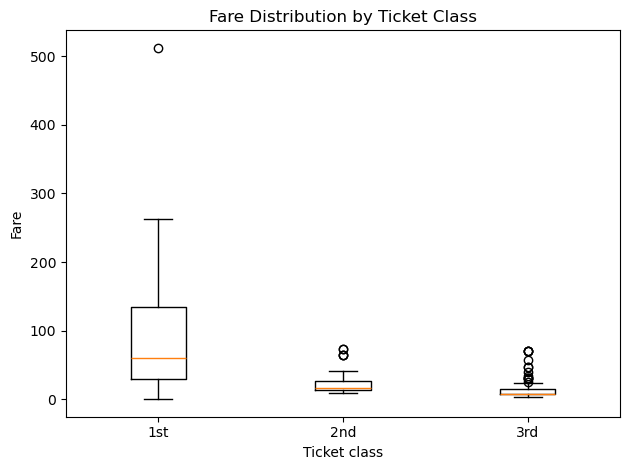

In [6]:
fare_groups = [
    df.loc[df["Pclass"] == ticket_class, "Fare"].dropna().to_numpy()
    for ticket_class in [1, 2, 3]
]

for ticket_class, fares in zip([1, 2, 3], fare_groups):
    print(f"Class {ticket_class}: count={fares.size}, median={np.median(fares):.2f}, mean={np.mean(fares):.2f}")

fig, ax = plt.subplots()
ax.boxplot(fare_groups)
ax.set_xticks([1, 2, 3], ["1st", "2nd", "3rd"])
ax.set_title("Fare Distribution by Ticket Class")
ax.set_xlabel("Ticket class")
ax.set_ylabel("Fare")
plt.tight_layout()
plt.show()


The plot compares fares recorded for each ticket class. It describes the distributions in the dataset; it does not explain why fares differ.


## 8. The complete workflow

The roles fit together in a repeatable order:

1. **pandas reads and organizes** the CSV into a labeled table.
2. **pandas inspects and filters** columns and handles missing entries for a particular calculation.
3. **NumPy calculates** summaries from numerical arrays.
4. **Matplotlib visualizes** counts, distributions, or ordered measurements.
5. **The analyst interprets** the result and states its limits.

For this passenger file, we can describe class counts, known ages, and recorded fares. Since there is no `Survived` column, we cannot calculate survival rates from this file.


## Summary

pandas is the table-handling tool, NumPy is the numerical calculation tool, and Matplotlib is the visualization tool. Together, they turn a CSV file into checked data, useful summaries, and charts that help communicate patterns. Good analysis also checks missing data, labels units, chooses a graph suited to the column types, and avoids conclusions the file cannot support.
